# Oxford-IIIT Pet: a full-spectrum Computer Vision project (PyTorch)

One dataset, **every major CV task**. The Oxford-IIIT Pet dataset (7,349 images, 37 cat/dog breeds) ships with breed labels *and* pixel-level trimaps, so we can derive bounding boxes from the masks and cover classification, localization and segmentation on the same images.

| # | Section | CV concept |
|---|---------|-----------|
| 1 | Data & EDA | datasets, splits, class balance, image statistics |
| 2 | Joint augmentation | geometric aug applied consistently to image + mask + box |
| 3 | CNN from scratch | convolutions, BatchNorm, pooling, baseline |
| 4 | Transfer learning | ImageNet pretraining, freezing, discriminative LRs, one-cycle schedule, label smoothing, AMP |
| 5 | Evaluation | top-k, confusion matrix, error analysis, calibration (ECE) |
| 6 | Grad-CAM | model explainability |
| 7 | Semantic segmentation | U-Net with pretrained ResNet-50 encoder, Dice/CE loss, mIoU |
| 8 | Multi-task learning | one backbone -> class + box + mask, GIoU loss |
| 9 | Object detection | pretrained Faster R-CNN vs. our box head |
| 10 | CNN vs Vision Transformer | fine-tune ViT-B/16 |
| 11 | Embeddings & retrieval | feature extraction, cosine search, t-SNE |
| 12 | Autoencoder | denoising, latent space interpolation (unsupervised / generative) |
| 13 | Robustness | accuracy under noise, blur, occlusion, low-res |
| 14 | Export & inference | ONNX, latency, predicting on your own photo |

**How to run:** works on Colab (GPU runtime) or locally. Set `FAST_DEV = True` in the config cell first to smoke-test the whole notebook in a few minutes on a tiny subset, then flip it to `False` for the real run. Expect roughly 40-70 minutes end-to-end on a T4 GPU.

In [1]:
!pip install -q torch torchvision scikit-learn matplotlib pandas tqdm onnx onnxruntime

import os, random, time, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.transforms import functional as TF
from torchvision.datasets import OxfordIIITPet
from torchvision.ops import generalized_box_iou_loss
from tqdm.auto import tqdm
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report

print("torch", torch.__version__, "| torchvision", torchvision.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 66.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 63.3 MB/s eta 0:00:00
torch 2.11.0+cu130 | torchvision 0.26.0+cu130


In [2]:
# ----------------------------- CONFIG -----------------------------
SEED = 42
FAST_DEV = False        # True = tiny subset + 1 epoch per stage (smoke test)
S = 224                 # image side length fed to every model
BATCH = 32
NUM_WORKERS = min(4, os.cpu_count() or 1)
DATA_ROOT = "./data"
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet stats

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

if torch.cuda.is_available():            DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():  DEVICE = torch.device("mps")
else:                                    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"          # automatic mixed precision (fp16) on NVIDIA GPUs
print("device:", DEVICE, "| AMP:", USE_AMP)

def E(n):                                # epochs helper: 1 epoch when FAST_DEV
    return 1 if FAST_DEV else n

def amp():
    return torch.autocast("cuda" if USE_AMP else "cpu", enabled=USE_AMP)

RESULTS = {}                             # every evaluation is logged here -> summary table at the end

device: cuda | AMP: True


## 1. Data & exploratory analysis

`OxfordIIITPet` gives us, per image: the **breed** (37 classes) and a **trimap** segmentation mask (1 = pet, 2 = background, 3 = border). We remap the trimap to labels `0 = pet, 1 = background, 2 = border`.

We hold out the official **test** split, and carve a validation set from `trainval` (85/15). *Never tune on the test set.*

In [3]:
base_trainval = OxfordIIITPet(DATA_ROOT, split="trainval", target_types=("category", "segmentation"), download=True)
base_test     = OxfordIIITPet(DATA_ROOT, split="test",     target_types=("category", "segmentation"), download=True)
CLASSES = base_trainval.classes
N_CLASSES = len(CLASSES)

CAT_BREEDS = {"abyssinian", "bengal", "birman", "bombay", "british shorthair", "egyptian mau",
              "maine coon", "persian", "ragdoll", "russian blue", "siamese", "sphynx"}
IS_CAT = np.array([c.lower() in CAT_BREEDS for c in CLASSES])   # used for a cat-vs-dog sanity metric
print(f"trainval={len(base_trainval)}  test={len(base_test)}  classes={N_CLASSES}  "
      f"({IS_CAT.sum()} cat breeds / {(~IS_CAT).sum()} dog breeds)")

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(base_trainval), generator=g).tolist()
n_val = int(0.15 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]
test_idx = list(range(len(base_test)))
if FAST_DEV:
    train_idx, val_idx, test_idx = train_idx[:128], val_idx[:64], test_idx[:64]
print("train/val/test sizes:", len(train_idx), len(val_idx), len(test_idx))

100%|██████████| 792M/792M [00:35<00:00, 22.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 15.2MB/s]


trainval=3680  test=3669  classes=37  (12 cat breeds / 25 dog breeds)
train/val/test sizes: 3128 552 3669


### 2. Dataset class with *joint* augmentation

For segmentation and localization the image, mask and box must be transformed **together**. We apply the same random flip / rotation / scale / translation to image (bilinear) and mask (nearest-neighbour), then **derive the bounding box from the final mask**, which keeps the box correct under any geometric augmentation. Colour jitter touches only the image.

In [4]:
BILINEAR, NEAREST = T.InterpolationMode.BILINEAR, T.InterpolationMode.NEAREST
_mean = torch.tensor(MEAN).view(3, 1, 1)
_std = torch.tensor(STD).view(3, 1, 1)
color_jitter = T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03)

def denorm(x):
    # normalized tensor (..., 3, H, W) -> [0, 1]; stays on the same device
    return (x * _std.to(x.device) + _mean.to(x.device)).clamp(0, 1)

def renorm(x01):
    return (x01 - _mean.to(x01.device)) / _std.to(x01.device)

def joint_transform(img, mask, train):
    img = img.convert("RGB")
    mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3
    img = TF.resize(img, [S, S], interpolation=BILINEAR)
    mask = TF.resize(mask, [S, S], interpolation=NEAREST)
    if train:
        if random.random() < 0.5:
            img, mask = TF.hflip(img), TF.hflip(mask)
        angle = random.uniform(-15, 15)
        scale = random.uniform(0.85, 1.2)
        tx = random.randint(-int(0.1 * S), int(0.1 * S))
        ty = random.randint(-int(0.1 * S), int(0.1 * S))
        img = TF.affine(img, angle=angle, translate=[tx, ty], scale=scale, shear=[0.0, 0.0],
                        interpolation=BILINEAR, fill=0)
        mask = TF.affine(mask, angle=angle, translate=[tx, ty], scale=scale, shear=[0.0, 0.0],
                         interpolation=NEAREST, fill=2)        # padded area counts as background
        img = color_jitter(img)
    x = TF.normalize(TF.to_tensor(img), MEAN, STD)
    m = (torch.from_numpy(np.array(mask)).long() - 1).clamp(0, 2)   # 0 pet, 1 background, 2 border
    return x, m

def mask_to_bbox(m):
    fg = m != 1                                   # pet or border
    if not fg.any():
        return torch.tensor([0.0, 0.0, 1.0, 1.0])
    ys = torch.where(fg.any(1))[0]
    xs = torch.where(fg.any(0))[0]
    return torch.tensor([xs.min().item() / S, ys.min().item() / S,
                         (xs.max().item() + 1) / S, (ys.max().item() + 1) / S])   # x1,y1,x2,y2 in [0,1]

class PetDataset(Dataset):
    def __init__(self, base, indices, train):
        self.base, self.indices, self.train = base, list(indices), train
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, (label, mask) = self.base[self.indices[i]]
        x, m = joint_transform(img, mask, self.train)
        return {"image": x, "label": torch.tensor(label, dtype=torch.long), "mask": m, "bbox": mask_to_bbox(m)}

train_ds = PetDataset(base_trainval, train_idx, train=True)
val_ds   = PetDataset(base_trainval, val_idx,   train=False)
test_ds  = PetDataset(base_test,     test_idx,  train=False)

def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, drop_last=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0)

train_dl, val_dl, test_dl = make_loader(train_ds, True), make_loader(val_ds, False), make_loader(test_ds, False)
b = next(iter(train_dl))
print({k: (tuple(v.shape), str(v.dtype)) for k, v in b.items()})

/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3
/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


{'image': ((32, 3, 224, 224), 'torch.float32'), 'label': ((32,), 'torch.int64'), 'mask': ((32, 224, 224), 'torch.int64'), 'bbox': ((32, 4), 'torch.float32')}


scanning 300 samples:   0%|          | 0/300 [00:00<?, ?it/s]

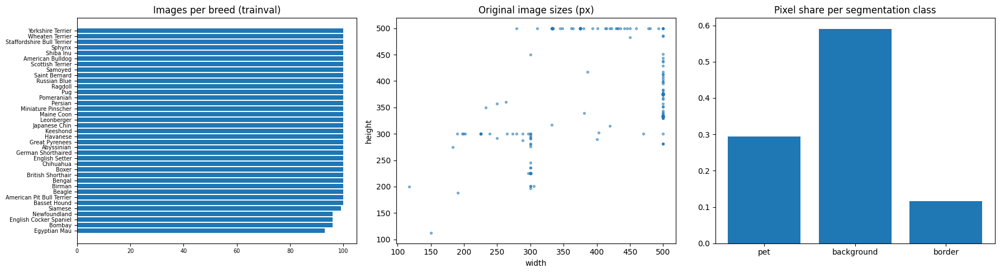

breed counts: min=93 max=100  -> nearly balanced
pixel share  pet/background/border: [0.294 0.591 0.116] -> segmentation is imbalanced (border is tiny)


In [5]:
# ---------------- EDA: class balance, image sizes, pixel balance ----------------
labels = np.array(base_trainval._labels)
counts = np.bincount(labels, minlength=N_CLASSES)

rng = np.random.default_rng(SEED)
sample = rng.choice(len(base_trainval), size=min(300, len(base_trainval)), replace=False)
sizes, pix = [], np.zeros(3)
for i in tqdm(sample, desc="scanning 300 samples", leave=False):
    img, (_, m) = base_trainval[int(i)]
    sizes.append(img.size)
    pix += np.bincount(np.array(m).ravel(), minlength=4)[1:4]
w, h = zip(*sizes)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
order = np.argsort(counts)
ax[0].barh(np.array(CLASSES)[order], counts[order]); ax[0].set_title("Images per breed (trainval)"); ax[0].tick_params(labelsize=7)
ax[1].scatter(w, h, s=8, alpha=0.5); ax[1].set_title("Original image sizes (px)"); ax[1].set_xlabel("width"); ax[1].set_ylabel("height")
ax[2].bar(["pet", "background", "border"], pix / pix.sum()); ax[2].set_title("Pixel share per segmentation class")
plt.tight_layout(); plt.show()
print(f"breed counts: min={counts.min()} max={counts.max()}  -> nearly balanced")
print("pixel share  pet/background/border:", np.round(pix / pix.sum(), 3), "-> segmentation is imbalanced (border is tiny)")

/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


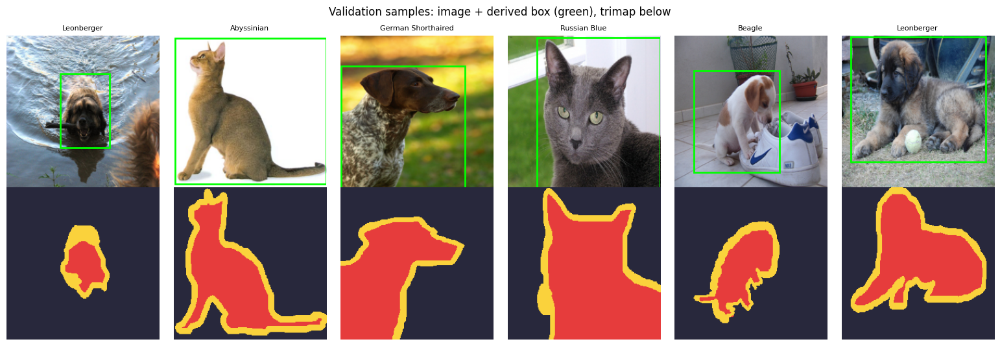

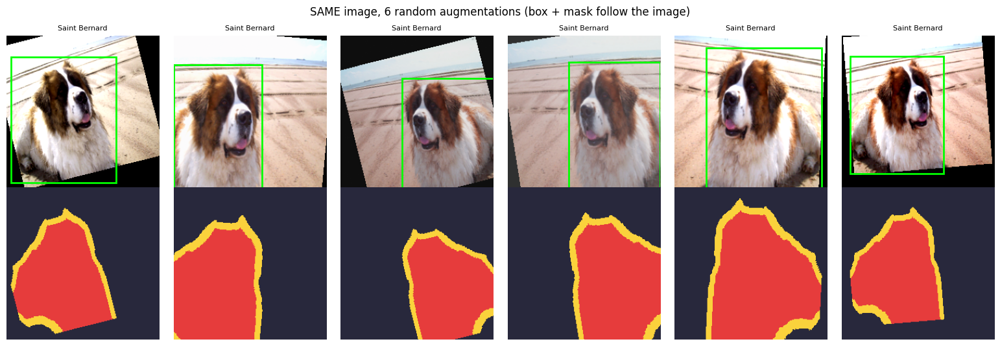

In [6]:
SEG_COLORS = np.array([[230, 60, 60], [40, 40, 60], [250, 210, 60]], dtype=np.uint8)   # pet, background, border

def draw_box(ax, box, color, lw=2):
    x1, y1, x2, y2 = [float(v) * S for v in box]
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=lw))

def show_samples(ds, idxs, title=""):
    fig, axes = plt.subplots(2, len(idxs), figsize=(2.6 * len(idxs), 5.4))
    for j, i in enumerate(idxs):
        d = ds[i]
        axes[0, j].imshow(denorm(d["image"]).permute(1, 2, 0).numpy())
        draw_box(axes[0, j], d["bbox"], "lime")
        axes[0, j].set_title(CLASSES[int(d["label"])], fontsize=8); axes[0, j].axis("off")
        axes[1, j].imshow(SEG_COLORS[d["mask"].numpy()]); axes[1, j].axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_samples(val_ds, list(range(6)), "Validation samples: image + derived box (green), trimap below")
show_samples(train_ds, [0] * 6, "SAME image, 6 random augmentations (box + mask follow the image)")

## 3. Training engine

One generic loop used by *every* model below. You pass a `step_fn(model, batch) -> (loss, stats)`; the engine handles AdamW, one-cycle LR, mixed precision, gradient clipping, validation, and restoring the best checkpoint.

**Concepts:** optimizer, LR schedule (one-cycle), weight decay, AMP / GradScaler, gradient clipping, early model selection.

In [7]:
def train_model(model, train_dl, val_dl, step_fn, epochs, groups, monitor, mode="max", wd=1e-4, name="model"):
    opt = torch.optim.AdamW(groups, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in groups], epochs=epochs,
                                                steps_per_epoch=len(train_dl), pct_start=0.2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist, best, best_state = [], None, None
    for ep in range(epochs):
        row = {"epoch": ep + 1}
        for phase, dl in (("train", train_dl), ("val", val_dl)):
            model.train(phase == "train")
            sums, n = {}, 0
            with torch.set_grad_enabled(phase == "train"):
                for batch in tqdm(dl, desc=f"{name} {phase} {ep + 1}/{epochs}", leave=False):
                    batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
                    with amp():
                        loss, stats = step_fn(model, batch)
                    if phase == "train":
                        opt.zero_grad(set_to_none=True)
                        scaler.scale(loss).backward()
                        scaler.unscale_(opt)
                        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        scaler.step(opt); scaler.update(); sched.step()
                    bs = batch["image"].size(0); n += bs
                    for k, v in {"loss": loss, **stats}.items():
                        sums[k] = sums.get(k, 0.0) + float(v) * bs
            for k, v in sums.items():
                row[f"{phase}_{k}"] = v / n
        hist.append(row)
        print(f"[{name}] ep {ep + 1}/{epochs} | " + " | ".join(f"{k} {v:.4f}" for k, v in row.items() if k != "epoch"))
        score = row[f"val_{monitor}"]
        if best is None or (score > best if mode == "max" else score < best):
            best = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    print(f"[{name}] restored best checkpoint (val_{monitor} = {best:.4f})")
    return pd.DataFrame(hist)

def plot_history(df, metrics, title=""):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.5))
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, metrics):
        ax.plot(df["epoch"], df[f"train_{m}"], label="train"); ax.plot(df["epoch"], df[f"val_{m}"], label="val")
        ax.set_title(f"{title} {m}"); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.show()

def make_cls_step(label_smoothing=0.0):
    def step(model, b):
        logits = model(b["image"]).float()
        loss = F.cross_entropy(logits, b["label"], label_smoothing=label_smoothing)
        return loss, {"acc": (logits.argmax(1) == b["label"]).float().mean()}
    return step

def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

## 4. Baseline: a CNN trained from scratch

A VGG-style stack: `[Conv-BN-ReLU] x2 -> MaxPool` repeated, then global average pooling and a linear classifier. With only ~3k training images and 37 classes it will **overfit and plateau low**, and that is the point: it shows what pretraining buys you in the next section.

**Concepts:** convolution, receptive field, BatchNorm, ReLU, pooling, global average pooling, overfitting.

SmallCNN params: 1.18M


scratch train 1/15:   0%|          | 0/97 [00:00<?, ?it/s]

/tmp/ipykernel_1510/263603407.py:25: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  sums[k] = sums.get(k, 0.0) + float(v) * bs
/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


scratch val 1/15:   0%|          | 0/18 [00:00<?, ?it/s]

/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


...

scratch val 14/15:   0%|          | 0/18 [00:00<?, ?it/s]

[scratch] ep 14/15 | train_loss 2.8873 | train_acc 0.2030 | val_loss 2.9996 | val_acc 0.1884


scratch train 15/15:   0%|          | 0/97 [00:00<?, ?it/s]

scratch val 15/15:   0%|          | 0/18 [00:00<?, ?it/s]

[scratch] ep 15/15 | train_loss 2.8347 | train_acc 0.2245 | val_loss 3.0066 | val_acc 0.1848
[scratch] restored best checkpoint (val_acc = 0.1884)


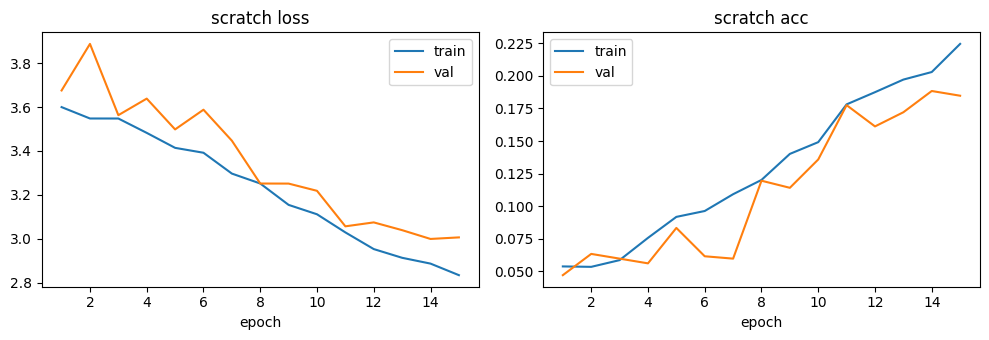

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes, widths=(32, 64, 128, 256)):
        super().__init__()
        blocks, c = [], 3
        for w_ in widths:
            blocks += [nn.Conv2d(c, w_, 3, padding=1, bias=False), nn.BatchNorm2d(w_), nn.ReLU(inplace=True),
                       nn.Conv2d(w_, w_, 3, padding=1, bias=False), nn.BatchNorm2d(w_), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c = w_
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(c, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

scratch = SmallCNN(N_CLASSES).to(DEVICE)
print(f"SmallCNN params: {count_params(scratch):.2f}M")
h_scratch = train_model(scratch, train_dl, val_dl, make_cls_step(0.0), epochs=E(15),
                        groups=[{"params": scratch.parameters(), "lr": 2e-3}], monitor="acc", name="scratch")
plot_history(h_scratch, ["loss", "acc"], "scratch")

## 5. Transfer learning with ResNet-50

Two-phase recipe that is the industry default:

1. **Feature extraction** - freeze the ImageNet backbone, train only the new classification head (fast, stable).
2. **Fine-tuning** - unfreeze everything with *discriminative learning rates* (small LR for pretrained layers, larger for the new head), one-cycle schedule, **label smoothing**.

**Concepts:** pretrained representations, freezing, discriminative LRs, label smoothing, regularization (dropout, weight decay).

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


ResNet-50 params: 23.6M


head-only train 1/3:   0%|          | 0/97 [00:00<?, ?it/s]

head-only val 1/3:   0%|          | 0/18 [00:00<?, ?it/s]

...

fine-tune val 7/8:   0%|          | 0/18 [00:00<?, ?it/s]

[fine-tune] ep 7/8 | train_loss 0.7107 | train_acc 0.9981 | val_loss 0.8081 | val_acc 0.9529


fine-tune train 8/8:   0%|          | 0/97 [00:00<?, ?it/s]

fine-tune val 8/8:   0%|          | 0/18 [00:00<?, ?it/s]

[fine-tune] ep 8/8 | train_loss 0.7077 | train_acc 0.9977 | val_loss 0.8064 | val_acc 0.9547
[fine-tune] restored best checkpoint (val_acc = 0.9547)


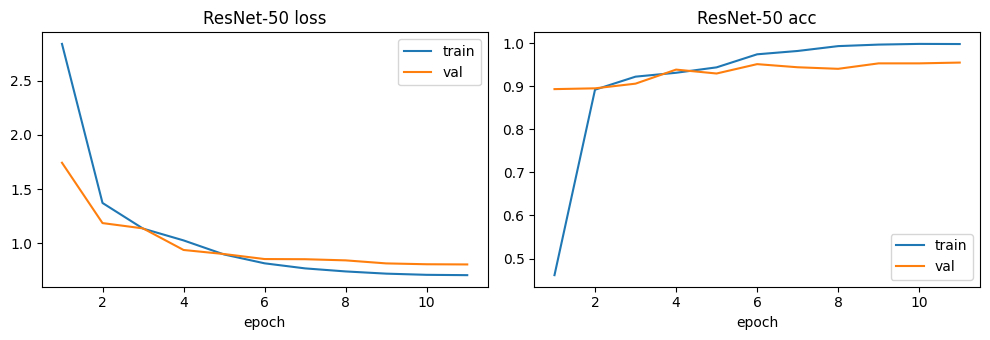

In [9]:
def make_resnet_classifier():
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, N_CLASSES))
    return m.to(DEVICE)

clf = make_resnet_classifier()
print(f"ResNet-50 params: {count_params(clf):.1f}M")

# ---- phase 1: head only
for p in clf.parameters(): p.requires_grad = False
for p in clf.fc.parameters(): p.requires_grad = True
h1 = train_model(clf, train_dl, val_dl, make_cls_step(0.1), epochs=E(3),
                 groups=[{"params": clf.fc.parameters(), "lr": 1e-3}], monitor="acc", name="head-only")

# ---- phase 2: full fine-tune, discriminative LRs
for p in clf.parameters(): p.requires_grad = True
backbone = [p for n, p in clf.named_parameters() if not n.startswith("fc.")]
h2 = train_model(clf, train_dl, val_dl, make_cls_step(0.1), epochs=E(8),
                 groups=[{"params": backbone, "lr": 1e-4}, {"params": clf.fc.parameters(), "lr": 1e-3}],
                 monitor="acc", name="fine-tune")
h_tl = pd.concat([h1, h2.assign(epoch=h2["epoch"] + len(h1))], ignore_index=True)
plot_history(h_tl, ["loss", "acc"], "ResNet-50")
torch.save(clf.state_dict(), "pet_resnet50_cls.pt")

## 6. Evaluation & error analysis

Accuracy alone is not enough. We report **top-1 / top-5**, a **cat-vs-dog** accuracy (do errors at least land in the right species?), **calibration (ECE)** (are confidences trustworthy?), a **confusion matrix**, the **most-confused breed pairs**, and the **most confident mistakes**.

In [10]:
@torch.no_grad()
def predict_logits(model, loader):
    model.eval(); outs, ys = [], []
    for b in loader:
        with amp():
            o = model(b["image"].to(DEVICE))
        outs.append(o.float().cpu()); ys.append(b["label"])
    return torch.cat(outs), torch.cat(ys)

def ece_score(probs, y, bins=15):
    conf, pred = probs.max(1); acc = (pred == y).float()
    edges = torch.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return e

def evaluate_classifier(model, loader, name):
    logits, y = predict_logits(model, loader)
    probs = logits.softmax(1); pred = probs.argmax(1)
    top1 = (pred == y).float().mean().item()
    top5 = (logits.topk(5, 1).indices == y[:, None]).any(1).float().mean().item()
    species = float((IS_CAT[pred.numpy()] == IS_CAT[y.numpy()]).mean())
    ece = ece_score(probs, y)
    RESULTS[name] = {"top1": top1, "top5": top5, "cat_vs_dog": species, "ECE": ece}
    print(f"{name:<22} top1 {top1:.4f} | top5 {top5:.4f} | cat-vs-dog {species:.4f} | ECE {ece:.4f}")
    return probs, y

_ = evaluate_classifier(scratch, test_dl, "Scratch CNN (test)")
probs_clf, y_test = evaluate_classifier(clf, test_dl, "ResNet-50 FT (test)")

/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3
/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


Scratch CNN (test)     top1 0.1758 | top5 0.5034 | cat-vs-dog 0.7258 | ECE 0.0339
ResNet-50 FT (test)    top1 0.9278 | top5 0.9916 | cat-vs-dog 0.9981 | ECE 0.0881


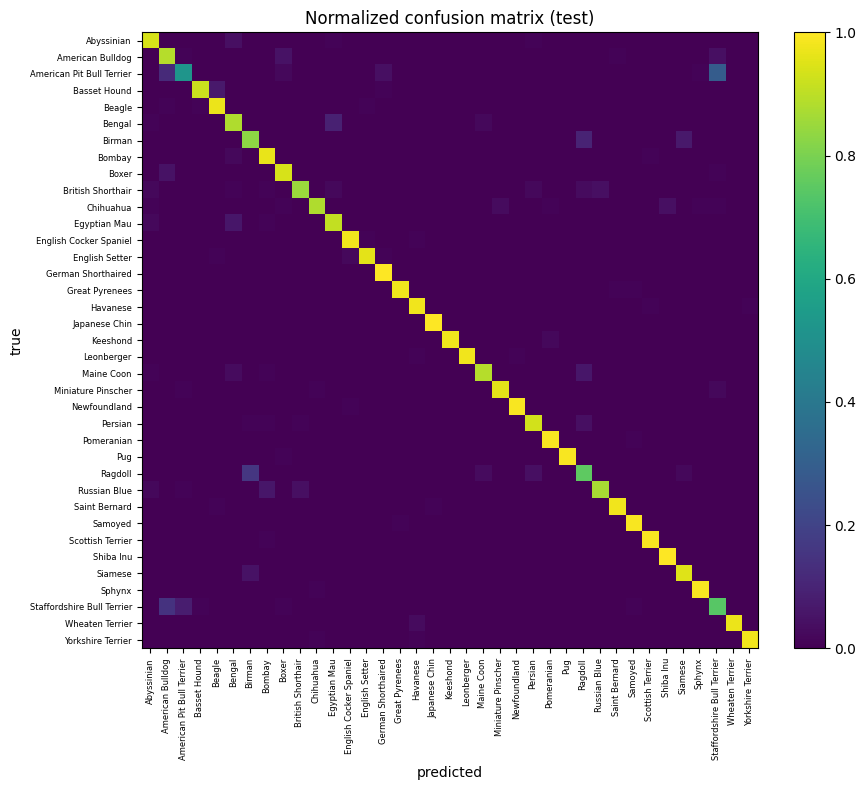

Most confused (true -> predicted):
  American Pit Bull Terrier    -> Staffordshire Bull Terrier   x29
  Ragdoll                      -> Birman                       x16
  Staffordshire Bull Terrier   -> American Bulldog             x13
  American Pit Bull Terrier    -> American Bulldog             x12
  Birman                       -> Ragdoll                      x10
  Bengal                       -> Egyptian Mau                 x9
  Basset Hound                 -> Beagle                       x7
  Staffordshire Bull Terrier   -> American Pit Bull Terrier    x7

Hardest breeds by F1: [('American Pit Bull Terrier', 0.64), ('Staffordshire Bull Terrier', 0.69), ('Ragdoll', 0.76), ('American Bulldog', 0.81), ('Birman', 0.81), ('Bengal', 0.86)]


/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


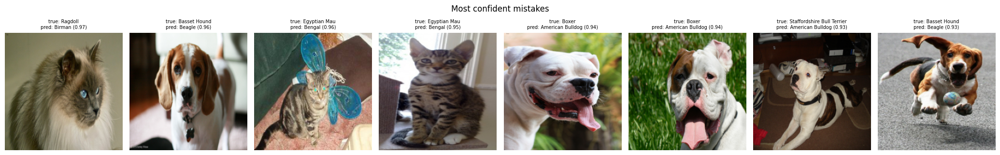

In [11]:
pred_clf = probs_clf.argmax(1).numpy(); yt = y_test.numpy()
cm = confusion_matrix(yt, pred_clf, labels=range(N_CLASSES))
cmn = cm / cm.sum(1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cmn, cmap="viridis"); plt.colorbar(im, fraction=0.046)
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels(CLASSES, rotation=90, fontsize=6); ax.set_yticklabels(CLASSES, fontsize=6)
ax.set_title("Normalized confusion matrix (test)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:8], off.shape))[0]
print("Most confused (true -> predicted):")
for t, p in pairs:
    if off[t, p] > 0:
        print(f"  {CLASSES[t]:<28} -> {CLASSES[p]:<28} x{off[t, p]}")

rep = classification_report(yt, pred_clf, labels=range(N_CLASSES), target_names=CLASSES, output_dict=True, zero_division=0)
worst = sorted(CLASSES, key=lambda c: rep[c]["f1-score"])[:6]
print("\nHardest breeds by F1:", [(c, round(rep[c]["f1-score"], 2)) for c in worst])

wrong = np.where(pred_clf != yt)[0]
conf_wrong = probs_clf.max(1).values.numpy()[wrong]
show = wrong[np.argsort(-conf_wrong)][:8]
if len(show):
    fig, axes = plt.subplots(1, len(show), figsize=(2.6 * len(show), 3.4))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, show):
        ax.imshow(denorm(test_ds[int(i)]["image"]).permute(1, 2, 0).numpy()); ax.axis("off")
        ax.set_title(f"true: {CLASSES[yt[i]]}\npred: {CLASSES[pred_clf[i]]} ({probs_clf[i].max():.2f})", fontsize=7)
    plt.suptitle("Most confident mistakes"); plt.tight_layout(); plt.show()

## 7. Explainability with Grad-CAM

*Where is the network looking?* Grad-CAM weights the last conv feature maps by the gradient of the class score, giving a coarse heatmap. We also compare the heatmap for the **predicted** (wrong) class with the **true** class on misclassified images, a very useful debugging habit.

**Concepts:** gradient-based attribution, feature maps, hooks, shortcut learning / spurious cues.

/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


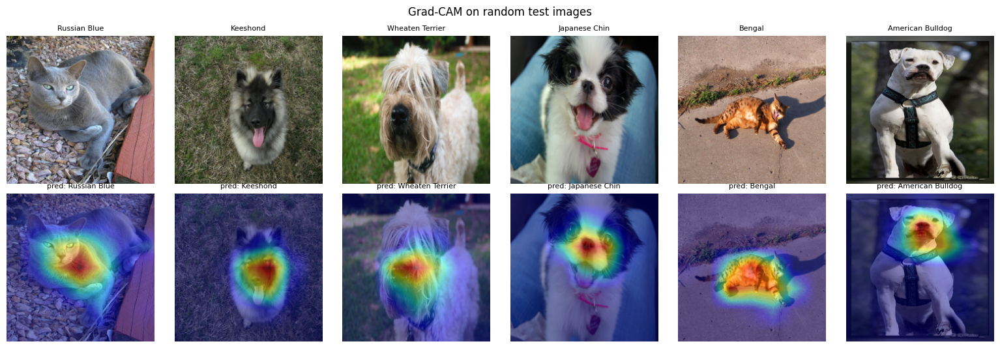

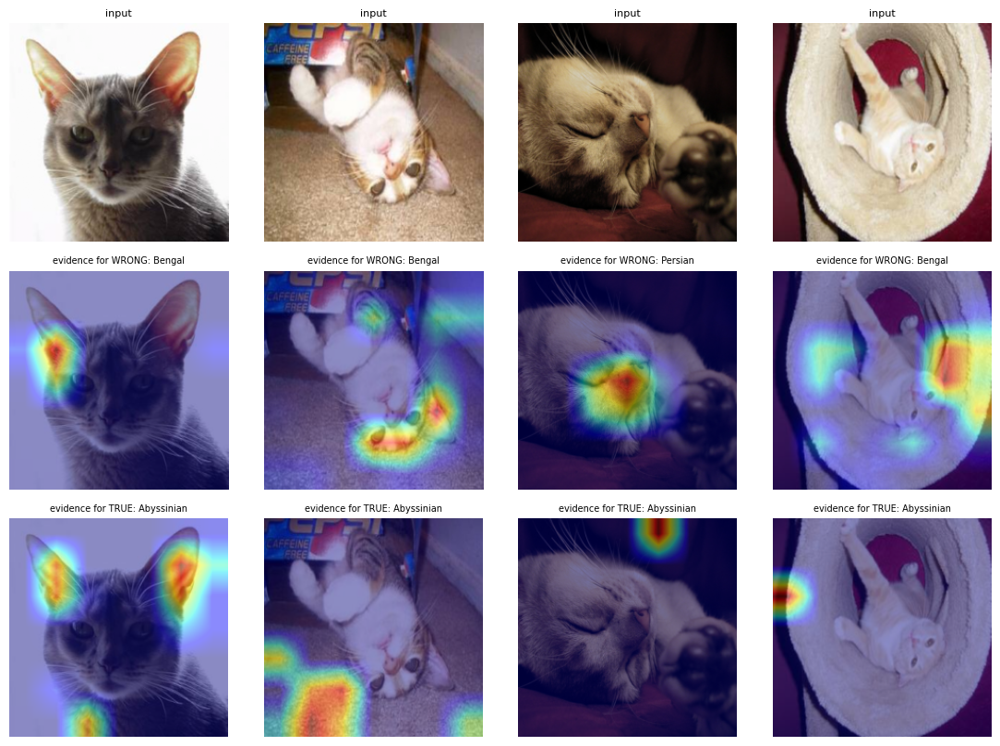

In [12]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval(); self.acts = None; self.grads = None
        def fwd_hook(module, inp, out):
            self.acts = out
            out.register_hook(lambda g: setattr(self, "grads", g))
        self.handle = target_layer.register_forward_hook(fwd_hook)
    def __call__(self, x, class_idx=None):
        self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            x = x.clone().requires_grad_(True)
            logits = self.model(x)
            if class_idx is None:
                class_idx = logits.argmax(1)
            score = logits.gather(1, class_idx[:, None]).sum()
            score.backward()
        with torch.no_grad():
            w_ = self.grads.mean((2, 3), keepdim=True)
            cam = F.relu((w_ * self.acts).sum(1, keepdim=True))
            cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
            cam = cam - cam.amin((2, 3), keepdim=True)
            cam = cam / (cam.amax((2, 3), keepdim=True) + 1e-8)
        return cam[:, 0].cpu(), logits.detach().cpu()
    def remove(self):
        self.handle.remove()

def overlay(img01, cam, alpha=0.45):
    heat = plt.cm.jet(cam.numpy())[..., :3]
    return (1 - alpha) * img01 + alpha * heat

gc = GradCAM(clf, clf.layer4[-1])
rng = np.random.default_rng(1)
idxs = rng.choice(len(test_ds), size=min(6, len(test_ds)), replace=False)
x = torch.stack([test_ds[int(i)]["image"] for i in idxs]).to(DEVICE)
cam, logits = gc(x)
fig, axes = plt.subplots(2, len(idxs), figsize=(2.6 * len(idxs), 5.4))
for j, i in enumerate(idxs):
    img01 = denorm(x[j].cpu()).permute(1, 2, 0).numpy()
    axes[0, j].imshow(img01); axes[0, j].axis("off"); axes[0, j].set_title(CLASSES[yt[i]], fontsize=8)
    axes[1, j].imshow(overlay(img01, cam[j])); axes[1, j].axis("off")
    axes[1, j].set_title(f"pred: {CLASSES[logits[j].argmax()]}", fontsize=8)
plt.suptitle("Grad-CAM on random test images"); plt.tight_layout(); plt.show()

if len(wrong):
    ws = wrong[:4]
    x = torch.stack([test_ds[int(i)]["image"] for i in ws]).to(DEVICE)
    cam_p, _ = gc(x, torch.tensor([pred_clf[i] for i in ws], device=DEVICE))
    cam_t, _ = gc(x, torch.tensor([yt[i] for i in ws], device=DEVICE))
    fig, axes = plt.subplots(3, len(ws), figsize=(2.8 * len(ws), 8.2))
    axes = axes.reshape(3, -1)
    for j, i in enumerate(ws):
        img01 = denorm(x[j].cpu()).permute(1, 2, 0).numpy()
        axes[0, j].imshow(img01); axes[0, j].set_title("input", fontsize=8)
        axes[1, j].imshow(overlay(img01, cam_p[j])); axes[1, j].set_title(f"evidence for WRONG: {CLASSES[pred_clf[i]]}", fontsize=7)
        axes[2, j].imshow(overlay(img01, cam_t[j])); axes[2, j].set_title(f"evidence for TRUE: {CLASSES[yt[i]]}", fontsize=7)
        for r in range(3): axes[r, j].axis("off")
    plt.tight_layout(); plt.show()
gc.remove()

## 8. Semantic segmentation: U-Net with a pretrained encoder

Classification says *what*; segmentation says *which pixels*. We build a **U-Net**: the ResNet-50 is the encoder (downsampling path, producing feature maps at 1/2, 1/4, 1/8, 1/16, 1/32 resolution), and a decoder upsamples back to full resolution, concatenating **skip connections** from the matching encoder stage.

* Loss = **cross-entropy + Dice** (Dice counters the class imbalance we saw in EDA).
* Metrics = **pixel accuracy, per-class IoU, mIoU, Dice**.

**Concepts:** encoder-decoder, skip connections, upsampling, Dice loss, IoU / mIoU, class imbalance.

U-Net params: 43.9M


unet train 1/10:   0%|          | 0/97 [00:00<?, ?it/s]

unet val 1/10:   0%|          | 0/18 [00:00<?, ?it/s]

[unet] ep 1/10 | train_loss 0.9621 | train_pix_acc 0.8500 | train_miou 0.6522 | val_loss 0.4343 | val_pix_acc 0.9144 | val_miou 0.7617


unet train 2/10:   0%|          | 0/97 [00:00<?, ?it/s]

...

unet val 9/10:   0%|          | 0/18 [00:00<?, ?it/s]

[unet] ep 9/10 | train_loss 0.2334 | train_pix_acc 0.9519 | train_miou 0.8440 | val_loss 0.2911 | val_pix_acc 0.9423 | val_miou 0.8205


unet train 10/10:   0%|          | 0/97 [00:00<?, ?it/s]

unet val 10/10:   0%|          | 0/18 [00:00<?, ?it/s]

[unet] ep 10/10 | train_loss 0.2282 | train_pix_acc 0.9532 | train_miou 0.8465 | val_loss 0.2904 | val_pix_acc 0.9423 | val_miou 0.8208
[unet] restored best checkpoint (val_miou = 0.8208)


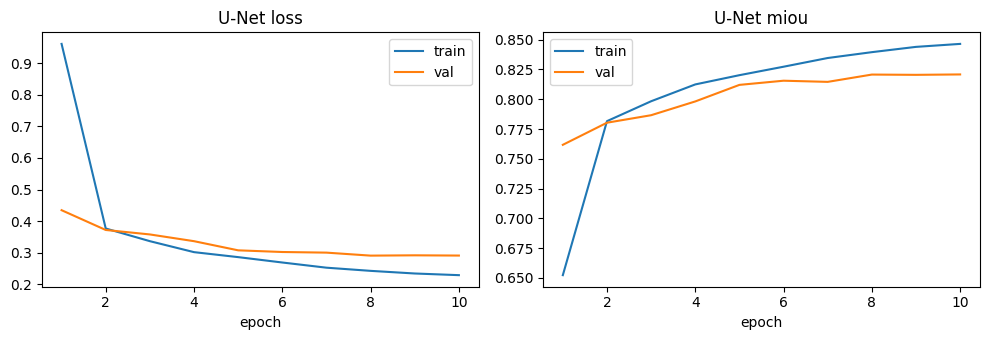

In [13]:
class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([x, skip], 1))

class ResNetUNet(nn.Module):
    def __init__(self, n_seg=3, pretrained=True):
        super().__init__()
        r = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)          # 1/2,  64 ch
        self.pool = r.maxpool
        self.enc1, self.enc2, self.enc3, self.enc4 = r.layer1, r.layer2, r.layer3, r.layer4   # 1/4:256, 1/8:512, 1/16:1024, 1/32:2048
        self.up4 = UpBlock(2048, 1024, 512)
        self.up3 = UpBlock(512, 512, 256)
        self.up2 = UpBlock(256, 256, 128)
        self.up1 = UpBlock(128, 64, 64)
        self.final = nn.Sequential(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                                   nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True), nn.Conv2d(32, n_seg, 1))
    def encode(self, x):
        s0 = self.stem(x)
        s1 = self.enc1(self.pool(s0)); s2 = self.enc2(s1); s3 = self.enc3(s2); s4 = self.enc4(s3)
        return s0, s1, s2, s3, s4
    def decode(self, feats):
        s0, s1, s2, s3, s4 = feats
        d = self.up4(s4, s3); d = self.up3(d, s2); d = self.up2(d, s1); d = self.up1(d, s0)
        return self.final(d)
    def forward(self, x):
        return self.decode(self.encode(x))
    def encoder_params(self):
        return [p for m in (self.stem, self.enc1, self.enc2, self.enc3, self.enc4) for p in m.parameters()]

def dice_loss(logits, target, eps=1e-6):
    probs = logits.softmax(1)
    onehot = F.one_hot(target, logits.size(1)).permute(0, 3, 1, 2).float()
    inter = (probs * onehot).sum((0, 2, 3)); den = probs.sum((0, 2, 3)) + onehot.sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (den + eps)).mean()

def batch_seg_stats(logits, mask):
    pred = logits.argmax(1)
    ious = []
    for c in range(3):
        inter = ((pred == c) & (mask == c)).sum().float(); union = ((pred == c) | (mask == c)).sum().float()
        if union > 0: ious.append(inter / union)
    return (pred == mask).float().mean(), torch.stack(ious).mean()

def seg_step(model, b):
    logits = model(b["image"]).float()
    loss = F.cross_entropy(logits, b["mask"]) + dice_loss(logits, b["mask"])
    pix, miou = batch_seg_stats(logits, b["mask"])
    return loss, {"pix_acc": pix, "miou": miou}

unet = ResNetUNet().to(DEVICE)
enc_ids = {id(p) for p in unet.encoder_params()}
dec_params = [p for p in unet.parameters() if id(p) not in enc_ids]
print(f"U-Net params: {count_params(unet):.1f}M")
h_seg = train_model(unet, train_dl, val_dl, seg_step, epochs=E(10),
                    groups=[{"params": unet.encoder_params(), "lr": 2e-4}, {"params": dec_params, "lr": 1e-3}],
                    monitor="miou", name="unet")
plot_history(h_seg, ["loss", "miou"], "U-Net")
torch.save(unet.state_dict(), "pet_unet.pt")

{'pixel_acc': 0.9424189329147339, 'mIoU': 0.8284998536109924, 'mDice': 0.8997816443443298, 'per_class_iou': {'pet': 0.9002, 'background': 0.9476, 'border': 0.6377}}


/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


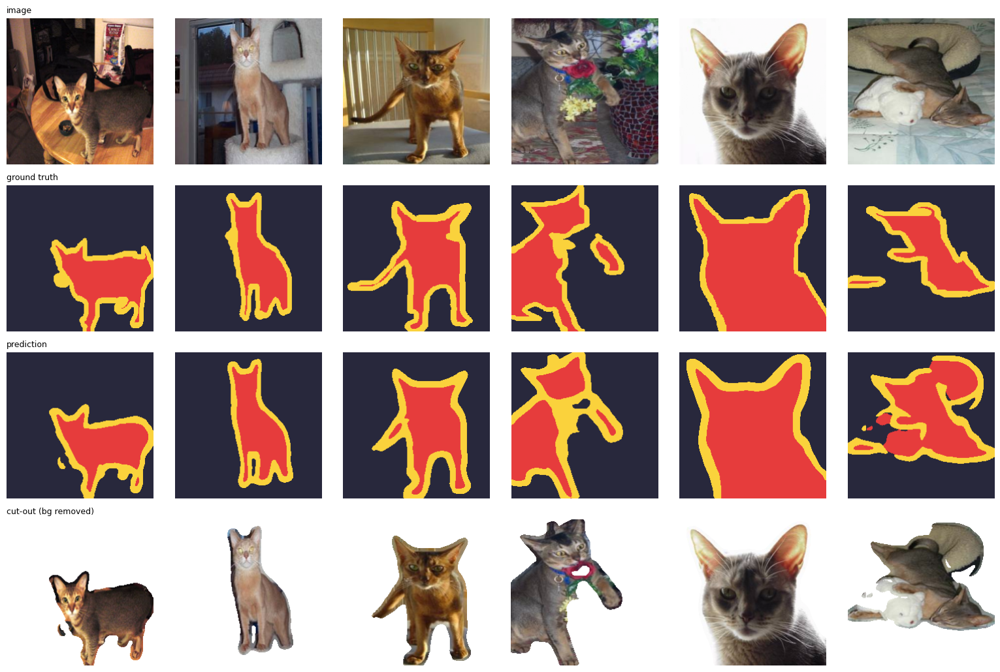

In [14]:
SEG_NAMES = ["pet", "background", "border"]

def conf_to_metrics(conf):
    tp = conf.diag().float()
    union = (conf.sum(0) + conf.sum(1)).float() - tp
    iou = tp / union.clamp(min=1)
    dice = 2 * tp / (conf.sum(0) + conf.sum(1)).float().clamp(min=1)
    return {"pixel_acc": (tp.sum() / conf.sum()).item(), "mIoU": iou.mean().item(),
            "mDice": dice.mean().item(), "per_class_iou": dict(zip(SEG_NAMES, [round(v, 4) for v in iou.tolist()]))}

@torch.no_grad()
def eval_seg(forward_seg, loader):
    conf = torch.zeros(3, 3, dtype=torch.long)
    for b in loader:
        with amp():
            logits = forward_seg(b["image"].to(DEVICE))
        pred = logits.argmax(1).cpu()
        conf += torch.bincount((b["mask"] * 3 + pred).flatten(), minlength=9).reshape(3, 3)
    return conf_to_metrics(conf)

unet.eval()
seg_metrics = eval_seg(unet, test_dl)
RESULTS["U-Net (test)"] = {k: v for k, v in seg_metrics.items() if k != "per_class_iou"}
print(seg_metrics)

@torch.no_grad()
def show_seg_predictions(forward_seg, ds, idxs):
    x = torch.stack([ds[i]["image"] for i in idxs]).to(DEVICE)
    with amp():
        pred = forward_seg(x).argmax(1).cpu()
    fig, axes = plt.subplots(4, len(idxs), figsize=(2.6 * len(idxs), 10.4))
    for j, i in enumerate(idxs):
        img01 = denorm(x[j].cpu()).permute(1, 2, 0).numpy()
        cutout = np.where((pred[j] != 1).numpy()[..., None], img01, 1.0)      # background removal
        axes[0, j].imshow(img01); axes[1, j].imshow(SEG_COLORS[ds[i]["mask"].numpy()])
        axes[2, j].imshow(SEG_COLORS[pred[j].numpy()]); axes[3, j].imshow(cutout)
        for r in range(4): axes[r, j].axis("off")
    for r, t in enumerate(["image", "ground truth", "prediction", "cut-out (bg removed)"]):
        axes[r, 0].set_title(t, fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

show_seg_predictions(unet, test_ds, list(range(0, min(6, len(test_ds)))))

## 9. Multi-task learning: classify + localize + segment with ONE backbone

A single shared ResNet-50 encoder feeds three heads:

* **classification head** (breed) - cross-entropy
* **box head** (single-object localization) - predicts `(cx, cy, w, h)` through a sigmoid, converted to `x1,y1,x2,y2`; loss = **L1 + GIoU**
* **segmentation decoder** (U-Net) - cross-entropy + Dice

Sharing the encoder acts as a regularizer and is far cheaper than three separate networks. Compare the numbers with the single-task models afterwards.

**Concepts:** multi-task learning, loss weighting, bounding-box regression, IoU / GIoU, parametrising boxes.

multitask train 1/12:   0%|          | 0/97 [00:00<?, ?it/s]

multitask val 1/12:   0%|          | 0/18 [00:00<?, ?it/s]

[multitask] ep 1/12 | train_loss 5.0963 | train_acc 0.2671 | train_box_iou 0.5960 | train_miou 0.6468 | val_loss 3.1214 | val_acc 0.8370 | val_box_iou 0.6573 | val_miou 0.7703


multitask train 2/12:   0%|          | 0/97 [00:00<?, ?it/s]

multitask val 2/12:   0%|          | 0/18 [00:00<?, ?it/s]

...

multitask val 11/12:   0%|          | 0/18 [00:00<?, ?it/s]

[multitask] ep 11/12 | train_loss 1.2152 | train_acc 0.9981 | train_box_iou 0.8671 | train_miou 0.8368 | val_loss 1.4197 | val_acc 0.9547 | val_box_iou 0.8453 | val_miou 0.8194


multitask train 12/12:   0%|          | 0/97 [00:00<?, ?it/s]

multitask val 12/12:   0%|          | 0/18 [00:00<?, ?it/s]

[multitask] ep 12/12 | train_loss 1.2057 | train_acc 0.9994 | train_box_iou 0.8690 | train_miou 0.8379 | val_loss 1.4144 | val_acc 0.9583 | val_box_iou 0.8460 | val_miou 0.8202
[multitask] restored best checkpoint (val_acc = 0.9638)


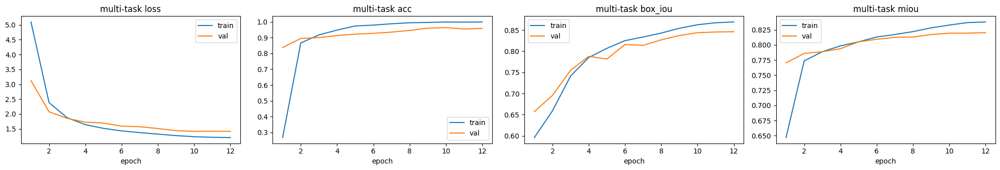

In [15]:
def box_iou_pairs(a, b):
    # element-wise IoU of two (N,4) tensors in x1,y1,x2,y2
    lt = torch.max(a[:, :2], b[:, :2]); rb = torch.min(a[:, 2:], b[:, 2:])
    inter = (rb - lt).clamp(min=0).prod(1)
    area = lambda t: (t[:, 2:] - t[:, :2]).clamp(min=0).prod(1)
    return inter / (area(a) + area(b) - inter + 1e-8)

class PetMultiTask(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.unet = ResNetUNet(n_seg=3)
        self.cls_head = nn.Sequential(nn.Dropout(0.2), nn.Linear(2048, n_classes))
        self.box_head = nn.Sequential(nn.Linear(2048, 512), nn.ReLU(inplace=True), nn.Dropout(0.1), nn.Linear(512, 4))
    def forward(self, x):
        feats = self.unet.encode(x)
        pooled = feats[4].mean((2, 3))
        seg = self.unet.decode(feats)
        cx, cy, bw, bh = self.box_head(pooled).float().sigmoid().unbind(1)
        box = torch.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], 1).clamp(0, 1)
        return {"cls": self.cls_head(pooled), "box": box, "seg": seg}

LAMBDA = {"cls": 1.0, "box": 1.0, "seg": 1.0}

def mt_step(model, b):
    out = model(b["image"])
    l_cls = F.cross_entropy(out["cls"].float(), b["label"], label_smoothing=0.1)
    box = out["box"].float()
    l_box = 5 * F.l1_loss(box, b["bbox"]) + generalized_box_iou_loss(box, b["bbox"], reduction="mean")
    seg = out["seg"].float()
    l_seg = F.cross_entropy(seg, b["mask"]) + dice_loss(seg, b["mask"])
    loss = LAMBDA["cls"] * l_cls + LAMBDA["box"] * l_box + LAMBDA["seg"] * l_seg
    _, miou = batch_seg_stats(seg, b["mask"])
    return loss, {"acc": (out["cls"].argmax(1) == b["label"]).float().mean(),
                  "box_iou": box_iou_pairs(box, b["bbox"]).mean(), "miou": miou}

multi = PetMultiTask(N_CLASSES).to(DEVICE)
enc_ids = {id(p) for p in multi.unet.encoder_params()}
rest = [p for p in multi.parameters() if id(p) not in enc_ids]
h_mt = train_model(multi, train_dl, val_dl, mt_step, epochs=E(12),
                   groups=[{"params": multi.unet.encoder_params(), "lr": 2e-4}, {"params": rest, "lr": 1e-3}],
                   monitor="acc", name="multitask")
plot_history(h_mt, ["loss", "acc", "box_iou", "miou"], "multi-task")
torch.save(multi.state_dict(), "pet_multitask.pt")

top1            0.9242
box_mean_IoU    0.8734
box_IoU>0.5     0.9894
mIoU            0.8262
pixel_acc       0.9412

Single-task vs multi-task
  breed top-1 : ResNet-50 FT 0.9278  vs  multi-task 0.9242
  seg mIoU    : U-Net       0.8285  vs  multi-task 0.8262


/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


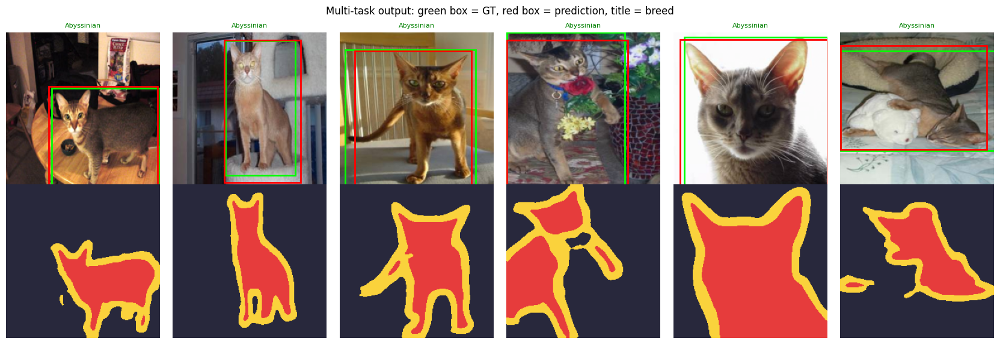

In [16]:
@torch.no_grad()
def eval_multitask(model, loader):
    model.eval(); correct = n = 0; ious = []; conf = torch.zeros(3, 3, dtype=torch.long)
    for b in loader:
        with amp():
            out = model(b["image"].to(DEVICE))
        correct += (out["cls"].argmax(1).cpu() == b["label"]).sum().item(); n += len(b["label"])
        ious.append(box_iou_pairs(out["box"].float().cpu(), b["bbox"]))
        conf += torch.bincount((b["mask"] * 3 + out["seg"].argmax(1).cpu()).flatten(), minlength=9).reshape(3, 3)
    ious = torch.cat(ious); seg = conf_to_metrics(conf)
    return {"top1": correct / n, "box_mean_IoU": ious.mean().item(), "box_IoU>0.5": (ious > 0.5).float().mean().item(),
            "mIoU": seg["mIoU"], "pixel_acc": seg["pixel_acc"]}

mt_metrics = eval_multitask(multi, test_dl)
RESULTS["Multi-task (test)"] = mt_metrics
print(pd.Series(mt_metrics).round(4).to_string())
print("\nSingle-task vs multi-task")
print(f"  breed top-1 : ResNet-50 FT {RESULTS['ResNet-50 FT (test)']['top1']:.4f}  vs  multi-task {mt_metrics['top1']:.4f}")
print(f"  seg mIoU    : U-Net       {RESULTS['U-Net (test)']['mIoU']:.4f}  vs  multi-task {mt_metrics['mIoU']:.4f}")

@torch.no_grad()
def show_multitask(model, ds, idxs):
    model.eval()
    x = torch.stack([ds[i]["image"] for i in idxs]).to(DEVICE)
    with amp():
        out = model(x)
    fig, axes = plt.subplots(2, len(idxs), figsize=(2.8 * len(idxs), 5.8))
    for j, i in enumerate(idxs):
        d = ds[i]; p = int(out["cls"][j].argmax()); ok = p == int(d["label"])
        axes[0, j].imshow(denorm(x[j].cpu()).permute(1, 2, 0).numpy())
        draw_box(axes[0, j], d["bbox"], "lime"); draw_box(axes[0, j], out["box"][j].float().cpu(), "red")
        axes[0, j].set_title(f"{CLASSES[p]}", fontsize=8, color="green" if ok else "red")
        axes[1, j].imshow(SEG_COLORS[out["seg"][j].argmax(0).cpu().numpy()])
        for r in range(2): axes[r, j].axis("off")
    plt.suptitle("Multi-task output: green box = GT, red box = prediction, title = breed"); plt.tight_layout(); plt.show()

show_multitask(multi, test_ds, list(range(min(6, len(test_ds)))))

## 10. Object detection with a pretrained detector

Our box head predicts **one** box per image. Real detectors (Faster R-CNN, YOLO, SSD, DETR) predict **many** boxes + classes per image, trained on COCO with anchors, region proposals / grid cells, and NMS. COCO already knows `cat` and `dog`, so we can run a pretrained **Faster R-CNN (MobileNetV3-FPN)** zero-shot and compare its localization quality with our custom box head on the same test images.

**Concepts:** anchors, region proposals, FPN, NMS, confidence thresholds, COCO, IoU@0.5.

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 164MB/s]
/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


Faster R-CNN (COCO, zero-shot): mean IoU 0.831 | IoU>0.5 0.958
Our multi-task box head      : mean IoU 0.872 | IoU>0.5 1.000


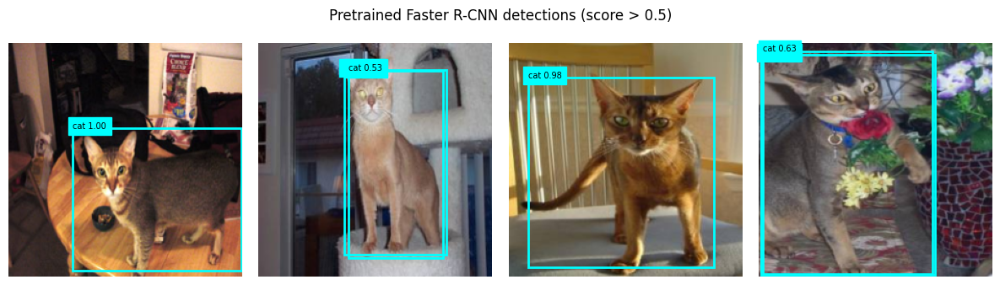

In [17]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights

DET_OK = True
try:
    det_w = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
    detector = fasterrcnn_mobilenet_v3_large_320_fpn(weights=det_w, box_score_thresh=0.3).to(DEVICE).eval()
    coco = det_w.meta["categories"]; pet_ids = [i for i, c in enumerate(coco) if c in ("cat", "dog")]
except Exception as e:
    DET_OK = False; print("Could not load the pretrained detector (offline?):", e)

if DET_OK:
    n_eval = min(120, len(test_ds)); det_iou, mt_iou = [], []; vis = []
    with torch.no_grad():
        for s in range(0, n_eval, 16):
            ids = list(range(s, min(s + 16, n_eval)))
            xs = torch.stack([test_ds[i]["image"] for i in ids]).to(DEVICE)
            outs = detector([denorm(x_) for x_ in xs])
            with amp():
                mt_out = multi.eval()(xs)
            for k, i in enumerate(ids):
                gt = (test_ds[i]["bbox"] * S)[None]
                o = outs[k]; keep = [j for j, l in enumerate(o["labels"].tolist()) if l in pet_ids]
                if keep:
                    j = max(keep, key=lambda q: o["scores"][q].item()); db = o["boxes"][j].cpu()[None]
                    det_iou.append(box_iou_pairs(db, gt).item())
                else:
                    det_iou.append(0.0)
                mt_iou.append(box_iou_pairs((mt_out["box"][k].float().cpu() * S)[None], gt).item())
                if len(vis) < 4: vis.append((i, o))
    det_iou, mt_iou = np.array(det_iou), np.array(mt_iou)
    RESULTS["Faster R-CNN zero-shot"] = {"box_mean_IoU": det_iou.mean(), "box_IoU>0.5": (det_iou > 0.5).mean()}
    print(f"Faster R-CNN (COCO, zero-shot): mean IoU {det_iou.mean():.3f} | IoU>0.5 {(det_iou > 0.5).mean():.3f}")
    print(f"Our multi-task box head      : mean IoU {mt_iou.mean():.3f} | IoU>0.5 {(mt_iou > 0.5).mean():.3f}")
    fig, axes = plt.subplots(1, len(vis), figsize=(3 * len(vis), 3.4))
    for ax, (i, o) in zip(np.atleast_1d(axes), vis):
        ax.imshow(denorm(test_ds[i]["image"]).permute(1, 2, 0).numpy()); ax.axis("off")
        for bx, l, sc in zip(o["boxes"].cpu(), o["labels"].cpu(), o["scores"].cpu()):
            if sc > 0.5:
                x1, y1, x2, y2 = bx.tolist()
                ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="cyan", linewidth=2))
                ax.text(x1, y1, f"{coco[int(l)]} {sc:.2f}", color="black", fontsize=7, backgroundcolor="cyan")
    plt.suptitle("Pretrained Faster R-CNN detections (score > 0.5)"); plt.tight_layout(); plt.show()

## 11. CNN vs Vision Transformer

Same task, different inductive bias. **ViT-B/16** cuts the image into 16x16 patches, embeds them as tokens, and applies self-attention. It has no built-in locality/translation bias, so it relies more on pretraining. We fine-tune it with a much smaller learning rate than the CNN.

**Concepts:** patch embedding, self-attention, positional embeddings, inductive bias, pretraining scale.

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:05<00:00, 60.8MB/s]


ViT-B/16 params: 85.8M


vit train 1/4:   0%|          | 0/97 [00:00<?, ?it/s]

vit val 1/4:   0%|          | 0/18 [00:00<?, ?it/s]

...

vit val 3/4:   0%|          | 0/18 [00:00<?, ?it/s]

[vit] ep 3/4 | train_loss 0.7589 | train_acc 0.9784 | val_loss 0.8321 | val_acc 0.9493


vit train 4/4:   0%|          | 0/97 [00:00<?, ?it/s]

vit val 4/4:   0%|          | 0/18 [00:00<?, ?it/s]

[vit] ep 4/4 | train_loss 0.7191 | train_acc 0.9945 | val_loss 0.8124 | val_acc 0.9565
[vit] restored best checkpoint (val_acc = 0.9565)


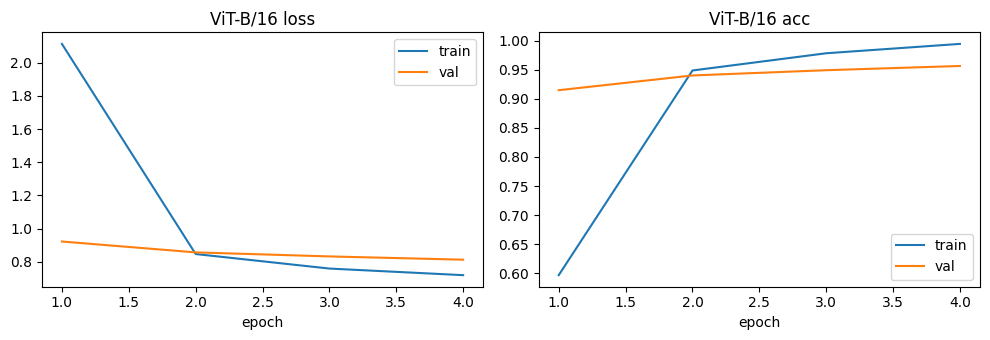

ViT-B/16 FT (test)     top1 0.9327 | top5 0.9956 | cat-vs-dog 0.9986 | ECE 0.1079


In [18]:
vit = torchvision.models.vit_b_16(weights=torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1)
vit.heads.head = nn.Linear(vit.heads.head.in_features, N_CLASSES)
vit = vit.to(DEVICE)
print(f"ViT-B/16 params: {count_params(vit):.1f}M")
head_params = list(vit.heads.parameters()); head_ids = {id(p) for p in head_params}
body = [p for p in vit.parameters() if id(p) not in head_ids]
h_vit = train_model(vit, train_dl, val_dl, make_cls_step(0.1), epochs=E(4),
                    groups=[{"params": body, "lr": 3e-5}, {"params": head_params, "lr": 1e-3}],
                    monitor="acc", wd=0.05, name="vit")
plot_history(h_vit, ["loss", "acc"], "ViT-B/16")
_ = evaluate_classifier(vit, test_dl, "ViT-B/16 FT (test)")

## 12. Embeddings & image retrieval

Strip the classification layer and a CNN becomes a **feature extractor**. Cosine similarity between 2048-d embeddings gives *content-based image retrieval* ("find similar pets") with **no extra training**. We measure retrieval **precision@5** and visualize the embedding space with **t-SNE**.

**Concepts:** representation learning, embeddings, cosine similarity, nearest-neighbour search, dimensionality reduction.

Retrieval precision@5 on the test set: 0.9187


/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


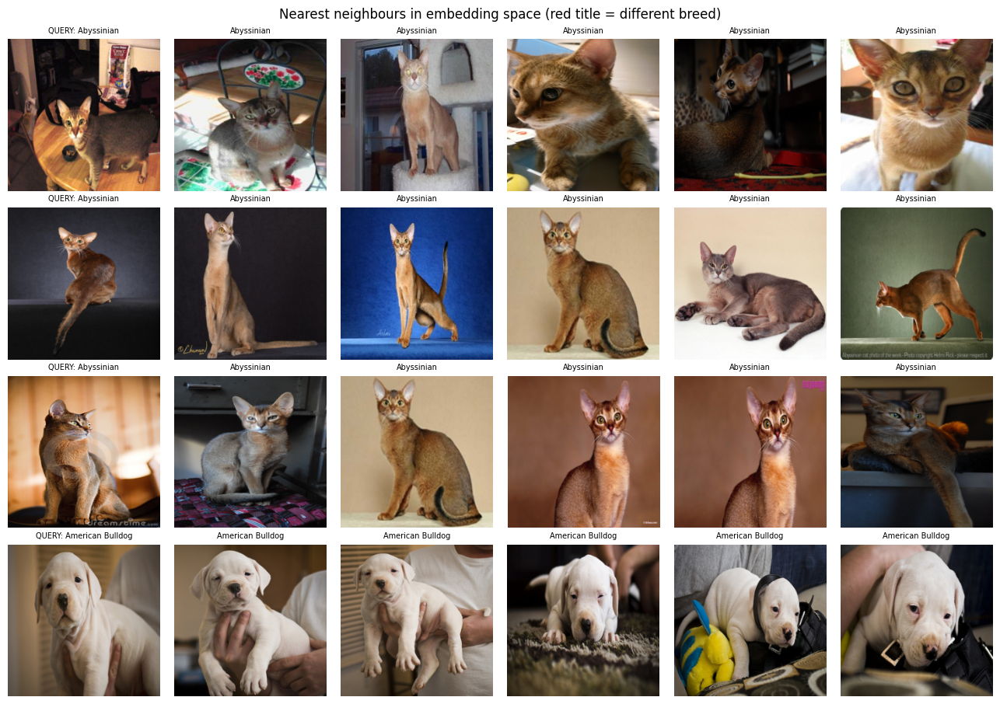

In [19]:
feat_model = copy.deepcopy(clf).to(DEVICE).eval()
feat_model.fc = nn.Identity()

@torch.no_grad()
def extract(model, loader):
    fs, ys = [], []
    for b in loader:
        with amp():
            fs.append(model(b["image"].to(DEVICE)).float().cpu())
        ys.append(b["label"])
    return torch.cat(fs), torch.cat(ys)

feats, ys = extract(feat_model, test_dl)
fn = F.normalize(feats, dim=1); sim = fn @ fn.T; sim.fill_diagonal_(-1)
nn5 = sim.topk(5, 1).indices
p5 = (ys[nn5] == ys[:, None]).float().mean().item()
RESULTS["Retrieval (test)"] = {"precision@5": p5}
print(f"Retrieval precision@5 on the test set: {p5:.4f}")

qs = list(range(0, min(len(test_ds), 4 * 37), 37))[:4] or [0]
fig, axes = plt.subplots(len(qs), 6, figsize=(13, 2.3 * len(qs)))
axes = np.atleast_2d(axes)
for r, q in enumerate(qs):
    row = [q] + nn5[q].tolist()
    for c, i in enumerate(row):
        axes[r, c].imshow(denorm(test_ds[i]["image"]).permute(1, 2, 0).numpy()); axes[r, c].axis("off")
        axes[r, c].set_title(("QUERY: " if c == 0 else "") + CLASSES[int(ys[i])], fontsize=7,
                             color="black" if c == 0 or ys[i] == ys[q] else "red")
plt.suptitle("Nearest neighbours in embedding space (red title = different breed)"); plt.tight_layout(); plt.show()

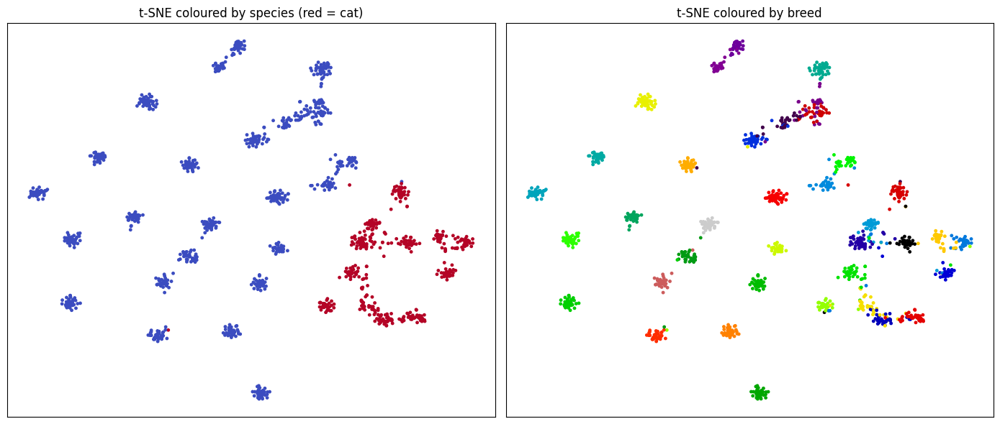

In [20]:
from sklearn.manifold import TSNE
m_ = min(1500, len(feats))
sel = np.random.default_rng(0).choice(len(feats), m_, replace=False)
emb = TSNE(n_components=2, init="pca", perplexity=min(30, max(5, m_ // 4)), random_state=0).fit_transform(feats[sel].numpy())
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].scatter(emb[:, 0], emb[:, 1], c=IS_CAT[ys[sel].numpy()], cmap="coolwarm", s=6); ax[0].set_title("t-SNE coloured by species (red = cat)")
ax[1].scatter(emb[:, 0], emb[:, 1], c=ys[sel].numpy(), cmap="nipy_spectral", s=6); ax[1].set_title("t-SNE coloured by breed")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 13. Unsupervised / generative: a denoising convolutional autoencoder

No labels at all. The network gets a **noisy** 64x64 image and must reconstruct the **clean** one through a narrow bottleneck (a 4x4x64 latent code), so it learns image structure. We then **interpolate between two latent codes** to see a (blurry) generative model in action.

**Concepts:** autoencoders, bottleneck/latent space, transposed convolutions, denoising, PSNR, latent interpolation (the road to VAEs/GANs/diffusion).

autoencoder train 1/15:   0%|          | 0/97 [00:00<?, ?it/s]

autoencoder val 1/15:   0%|          | 0/18 [00:00<?, ?it/s]

[autoencoder] ep 1/15 | train_loss 0.0582 | train_psnr 12.6962 | val_loss 0.0234 | val_psnr 16.3282


autoencoder train 2/15:   0%|          | 0/97 [00:00<?, ?it/s]

autoencoder val 2/15:   0%|          | 0/18 [00:00<?, ?it/s]

...

autoencoder val 14/15:   0%|          | 0/18 [00:00<?, ?it/s]

[autoencoder] ep 14/15 | train_loss 0.0061 | train_psnr 22.1423 | val_loss 0.0059 | val_psnr 22.2989


autoencoder train 15/15:   0%|          | 0/97 [00:00<?, ?it/s]

autoencoder val 15/15:   0%|          | 0/18 [00:00<?, ?it/s]

[autoencoder] ep 15/15 | train_loss 0.0061 | train_psnr 22.1606 | val_loss 0.0059 | val_psnr 22.3116
[autoencoder] restored best checkpoint (val_loss = 0.0059)


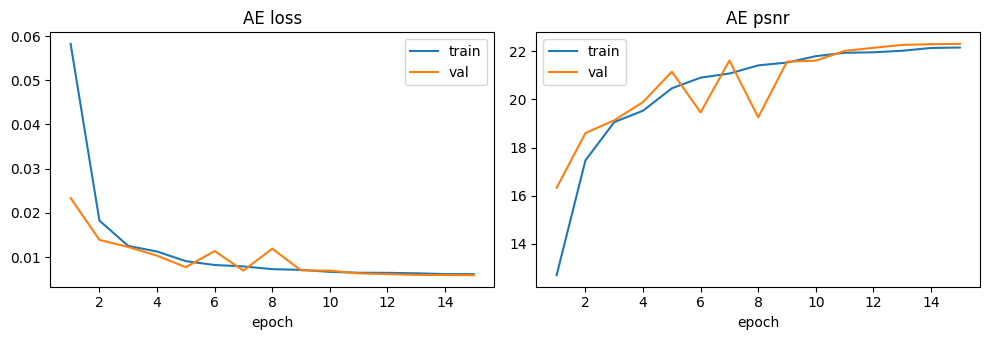

In [21]:
class ConvAE(nn.Module):
    def __init__(self, z=64):
        super().__init__()
        down = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True))
        up = lambda i, o: nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.ReLU(True))
        self.enc = nn.Sequential(down(3, 32), down(32, 64), down(64, 128), down(128, z))          # 64 -> 4
        self.dec = nn.Sequential(up(z, 128), up(128, 64), up(64, 32), nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())
    def forward(self, x):
        return self.dec(self.enc(x))

NOISE = 0.2
def ae_prepare(b):
    clean = F.interpolate(denorm(b["image"]), size=64, mode="area")
    noisy = (clean + NOISE * torch.randn_like(clean)).clamp(0, 1)
    return noisy, clean

def ae_step(model, b):
    noisy, clean = ae_prepare(b)
    recon = model(noisy).float()
    mse = F.mse_loss(recon, clean)
    return mse, {"psnr": -10 * torch.log10(mse.detach() + 1e-8)}

ae = ConvAE().to(DEVICE)
h_ae = train_model(ae, train_dl, val_dl, ae_step, epochs=E(15), groups=[{"params": ae.parameters(), "lr": 2e-3}],
                   monitor="loss", mode="min", name="autoencoder")
plot_history(h_ae, ["loss", "psnr"], "AE")
RESULTS["Denoising AE (val)"] = {"PSNR_dB": float(h_ae["val_psnr"].iloc[-1])}

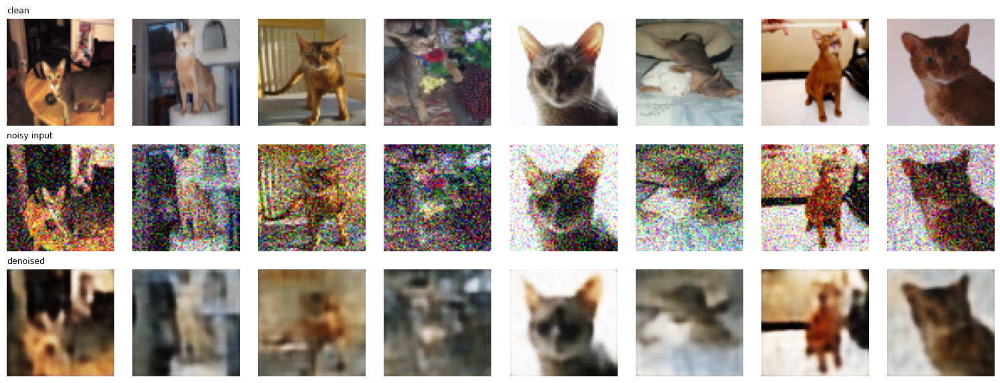

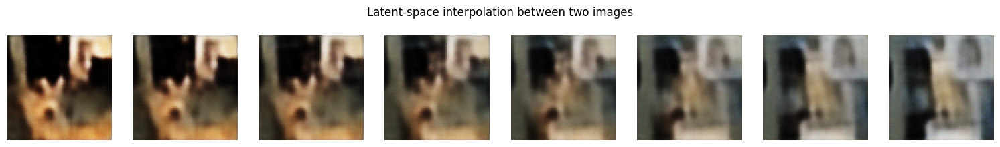

In [22]:
ae.eval()
with torch.no_grad():
    b = next(iter(test_dl)); b = {k: v.to(DEVICE) for k, v in b.items()}
    noisy, clean = ae_prepare(b); recon = ae(noisy)
    n_show = 8
    fig, axes = plt.subplots(3, n_show, figsize=(1.9 * n_show, 5.8))
    for j in range(n_show):
        for r, t in enumerate([clean, noisy, recon]):
            axes[r, j].imshow(t[j].cpu().permute(1, 2, 0).numpy()); axes[r, j].axis("off")
    for r, t in enumerate(["clean", "noisy input", "denoised"]): axes[r, 0].set_title(t, fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

    # latent interpolation between two images
    z = ae.enc(clean[:2]); steps = 8
    blend = torch.cat([(1 - a) * z[0:1] + a * z[1:2] for a in torch.linspace(0, 1, steps)])
    gen = ae.dec(blend).cpu()
    fig, axes = plt.subplots(1, steps, figsize=(1.9 * steps, 2.2))
    for j in range(steps): axes[j].imshow(gen[j].permute(1, 2, 0).numpy()); axes[j].axis("off")
    plt.suptitle("Latent-space interpolation between two images"); plt.tight_layout(); plt.show()

## 14. Robustness: what happens when images get worse?

Test accuracy on clean images overstates real-world performance. We corrupt the test images at 4 severity levels (**noise, blur, darkening, occlusion, pixelation**) and compare the **ResNet-50 (CNN)** against the **ViT**.

**Concepts:** distribution shift, corruption benchmarks (ImageNet-C idea), occlusion, robustness of CNNs vs transformers.

/tmp/ipykernel_1510/3346556028.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask = Image.fromarray(np.array(mask).astype(np.uint8), mode="L")   # raw trimap values 1/2/3


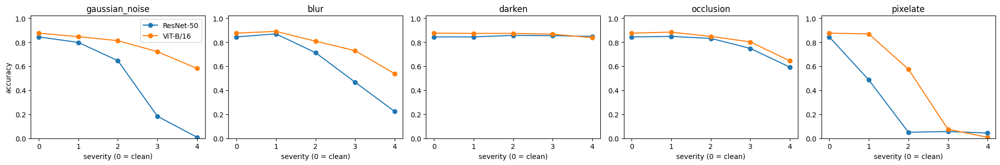

{'ResNet-50': 0.5481250000000001, 'ViT-B/16': 0.7039583333333332}


In [23]:
CORRUPTIONS = {"gaussian_noise": [0.05, 0.1, 0.2, 0.3], "blur": [1.0, 2.0, 3.0, 5.0], "darken": [0.8, 0.6, 0.4, 0.25],
               "occlusion": [0.15, 0.3, 0.45, 0.6], "pixelate": [2, 4, 8, 16]}

def corrupt(x01, kind, p):
    if kind == "gaussian_noise":
        return (x01 + torch.randn_like(x01) * p).clamp(0, 1)
    if kind == "blur":
        k = 2 * int(3 * p) + 1
        return TF.gaussian_blur(x01, kernel_size=[k, k], sigma=[p, p])
    if kind == "darken":
        return x01 * p
    if kind == "occlusion":
        out = x01.clone(); k = int(S * p)
        for i in range(out.size(0)):
            y0, x0 = random.randint(0, S - k), random.randint(0, S - k)
            out[i, :, y0:y0 + k, x0:x0 + k] = 0.5
        return out
    if kind == "pixelate":
        small = F.interpolate(x01, size=S // int(p), mode="area")
        return F.interpolate(small, size=S, mode="nearest")

n_rob = min(480, len(test_ds))
X = torch.stack([test_ds[i]["image"] for i in range(n_rob)]); Y = torch.stack([test_ds[i]["label"] for i in range(n_rob)])

@torch.no_grad()
def acc_on(model, kind=None, p=None, bs=48):
    model.eval(); correct = 0
    for i in range(0, len(X), bs):
        x_ = X[i:i + bs].to(DEVICE)
        if kind: x_ = renorm(corrupt(denorm(x_), kind, p))
        with amp():
            out = model(x_)
        correct += (out.argmax(1).cpu() == Y[i:i + bs]).sum().item()
    return correct / len(X)

models_rob = {"ResNet-50": clf, "ViT-B/16": vit}
rob = {m: {k: [acc_on(mod)] + [acc_on(mod, k, p) for p in ps] for k, ps in CORRUPTIONS.items()} for m, mod in models_rob.items()}
fig, axes = plt.subplots(1, len(CORRUPTIONS), figsize=(4 * len(CORRUPTIONS), 3.4))
for ax, k in zip(axes, CORRUPTIONS):
    for m in models_rob: ax.plot(range(5), rob[m][k], marker="o", label=m)
    ax.set_title(k); ax.set_xlabel("severity (0 = clean)"); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("accuracy"); axes[0].legend(); plt.tight_layout(); plt.show()
RESULTS["Robustness (mean acc, sev 1-4)"] = {m: float(np.mean([v[1:] for v in rob[m].values()])) for m in models_rob}
print(RESULTS["Robustness (mean acc, sev 1-4)"])

## 15. Export, inference on your own photo, and latency

Training is half the job. Here we **export to ONNX** (portable to ONNX Runtime, TensorRT, mobile, browsers), verify numerical parity, **benchmark latency**, and provide a `predict` helper you can point at any image file or URL.

**Concepts:** model serialization, ONNX, inference vs training mode, latency vs throughput, preprocessing parity.

In [24]:
import onnxruntime as ort

cpu_model = copy.deepcopy(clf).cpu().eval()
dummy = torch.randn(1, 3, S, S)
try:
    torch.onnx.export(cpu_model, dummy, "pet_resnet50_cls.onnx", input_names=["image"], output_names=["logits"],
                      dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
    sess = ort.InferenceSession("pet_resnet50_cls.onnx", providers=["CPUExecutionProvider"])
    x_ = torch.randn(4, 3, S, S)
    diff = np.abs(sess.run(None, {"image": x_.numpy()})[0] - cpu_model(x_).detach().numpy()).max()
    print(f"ONNX exported. max |torch - onnxruntime| = {diff:.2e}")
except Exception as e:
    print("ONNX export skipped:", e)

@torch.no_grad()
def bench(model, bs, iters=20):
    model.eval(); x_ = torch.randn(bs, 3, S, S, device=DEVICE)
    for _ in range(3): model(x_)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(iters): model(x_)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / iters * 1000
print(f"ResNet-50 latency on {DEVICE}: batch 1 = {bench(clf, 1):.1f} ms | batch 32 = {bench(clf, 32):.1f} ms")

ONNX export skipped: No module named 'onnxscript'
ResNet-50 latency on cuda: batch 1 = 7.4 ms | batch 32 = 98.7 ms


In [25]:
from urllib.request import urlopen
import io

IMAGE_SOURCE = None   # <- put a file path or an http(s) URL of your own pet photo here, e.g. "my_dog.jpg"

@torch.no_grad()
def predict(source, topk=5):
    if source.startswith("http"):
        img = Image.open(io.BytesIO(urlopen(source).read())).convert("RGB")
    else:
        img = Image.open(source).convert("RGB")
    x = TF.normalize(TF.to_tensor(TF.resize(img, [S, S], interpolation=BILINEAR)), MEAN, STD)[None].to(DEVICE)
    multi.eval()
    with amp():
        out = multi(x)
    probs = out["cls"].float().softmax(1)[0].cpu(); top = probs.topk(topk)
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].imshow(img.resize((S, S))); draw_box(ax[0], out["box"][0].float().cpu(), "red"); ax[0].set_title("input + predicted box"); ax[0].axis("off")
    ax[1].imshow(SEG_COLORS[out["seg"][0].argmax(0).cpu().numpy()]); ax[1].set_title("predicted segmentation"); ax[1].axis("off")
    ax[2].barh([CLASSES[i] for i in top.indices][::-1], top.values.numpy()[::-1]); ax[2].set_title("top predictions")
    plt.tight_layout(); plt.show()

predict(IMAGE_SOURCE) if IMAGE_SOURCE else print("Set IMAGE_SOURCE above to try your own photo.")

Set IMAGE_SOURCE above to try your own photo.


## 16. Final scoreboard

In [26]:
summary = pd.DataFrame({k: pd.Series(v) for k, v in RESULTS.items()}).T
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
display(summary)
with open("results_pytorch.json", "w") as f:
    json.dump({k: {a: float(b) for a, b in v.items()} for k, v in RESULTS.items()}, f, indent=2)
print("saved results_pytorch.json")

,ECE,PSNR_dB,ResNet-50,ViT-B/16,box_IoU>0.5,box_mean_IoU,cat_vs_dog,mDice,mIoU,pixel_acc,precision@5,top1,top5
Scratch CNN (test),0.0339,NaN,NaN,NaN,NaN,NaN,0.7258,NaN,NaN,NaN,NaN,0.1758,0.5034
ResNet-50 FT (test),0.0881,NaN,NaN,NaN,NaN,NaN,0.9981,NaN,NaN,NaN,NaN,0.9278,0.9916
U-Net (test),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.8998,0.8285,0.9424,NaN,NaN,NaN
Multi-task (test),NaN,NaN,NaN,NaN,0.9894,0.8734,NaN,NaN,0.8262,0.9412,NaN,0.9242,NaN
Faster R-CNN zero-shot,NaN,NaN,NaN,NaN,0.9583,0.8309,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ViT-B/16 FT (test),0.1079,NaN,NaN,NaN,NaN,NaN,0.9986,NaN,NaN,NaN,NaN,0.9327,0.9956
Retrieval (test),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9187,NaN,NaN
Denoising AE (val),NaN,22.3116,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"Robustness (mean acc, sev 1-4)",NaN,NaN,0.5481,0.7040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


saved results_pytorch.json


### Where to go next
* **Self-supervised learning** (SimCLR / DINO) on the unlabeled images, then linear-probe the features.
* **Instance segmentation** (Mask R-CNN) and **keypoints / landmarks**.
* **Diffusion / GAN** generation, **CLIP** zero-shot classification and text-to-image retrieval.
* **Hyper-parameter search** (Optuna), **loss-weight ablations** for the multi-task model, **K-fold CV**.
* **Knowledge distillation** and **quantization** to shrink the model for mobile.